In [8]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
ramps_results_path = Path('/Volumes/INCR-NolanLab/ActiveProjects/Yiming/NWR1/analysis/ramps/combined/ramps_classification.csv')
df = pd.read_csv(ramps_results_path)

In [23]:
# filter out the rows where si is < 0
df_filtered = df[df['spatial_information'] >= 0]

In [38]:
df_filtered.head()

,nwb_path,experiment,mouse,day,unit_id,session,trial_type,test_block,reward_position,_ramps_smooth_sigma,...,homebound_sig,homebound_sign,outbound_valid_bins,homebound_valid_bins,spatial_information,_si_smooth_sigma,si_sig,si_pval,genotype,ramp_type
0,/exports/eddie/scratch/s2155699/ephys/ramps/ra...,NWR1,M01,D22,1,VR,0,0,"(90, 110)","(np.float64(1.0),)",...,False,/,True,True,0.856509,"(2,)",False,0.045908,NaN,//
1,/exports/eddie/scratch/s2155699/ephys/ramps/ra...,NWR1,M01,D22,1,VR,0,1,"(90, 110)","(np.float64(1.0),)",...,True,-,True,True,0.319662,"(2,)",False,0.331337,NaN,/-
2,/exports/eddie/scratch/s2155699/ephys/ramps/ra...,NWR1,M01,D22,1,VR,0,2,"(90, 110)","(np.float64(1.0),)",...,False,/,True,True,0.302244,"(2,)",False,0.624750,NaN,//
3,/exports/eddie/scratch/s2155699/ephys/ramps/ra...,NWR1,M01,D22,1,VR,1,0,"(90, 110)","(np.float64(1.0),)",...,False,/,True,True,0.029803,"(2,)",False,0.167665,NaN,//
4,/exports/eddie/scratch/s2155699/ephys/ramps/ra...,NWR1,M01,D22,1,VR,1,1,"(90, 110)","(np.float64(1.0),)",...,False,/,True,True,0.009026,"(2,)",False,0.622754,NaN,//


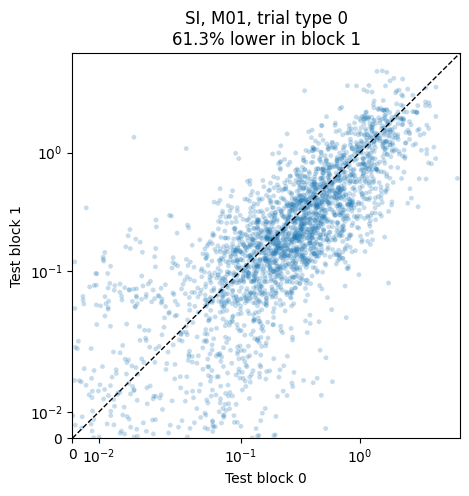

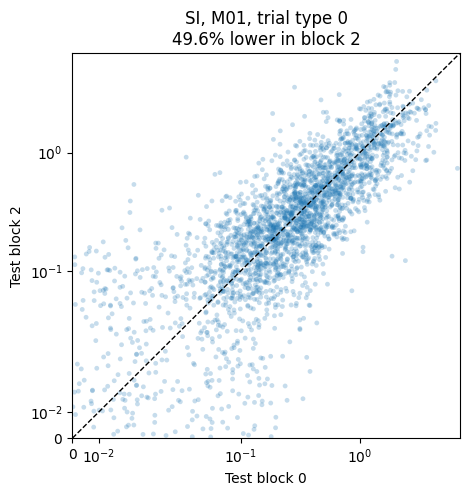

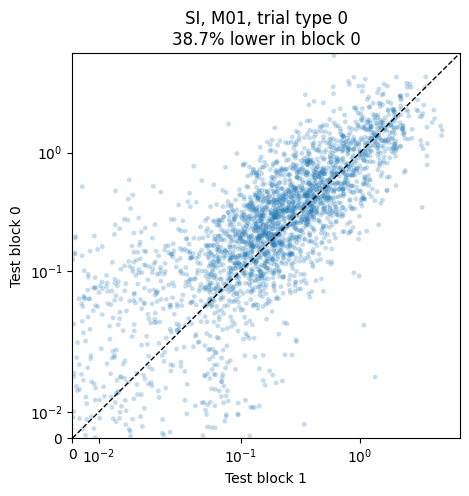

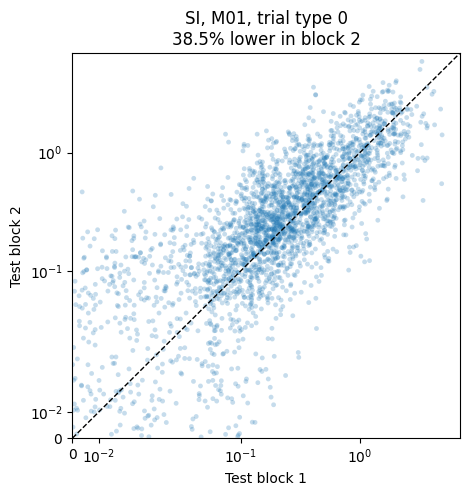

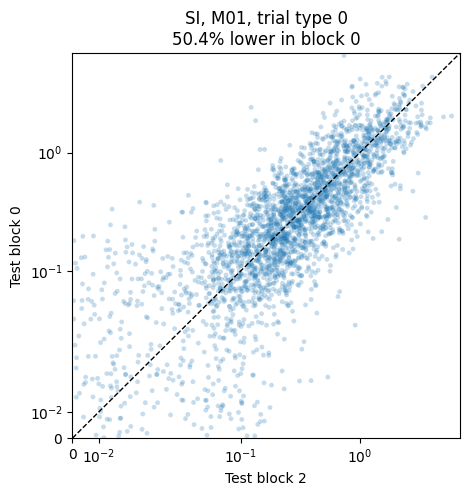

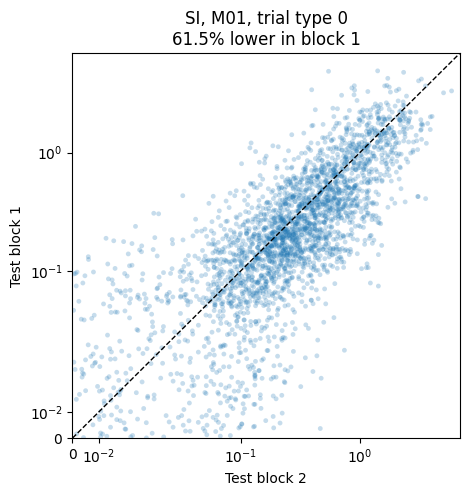

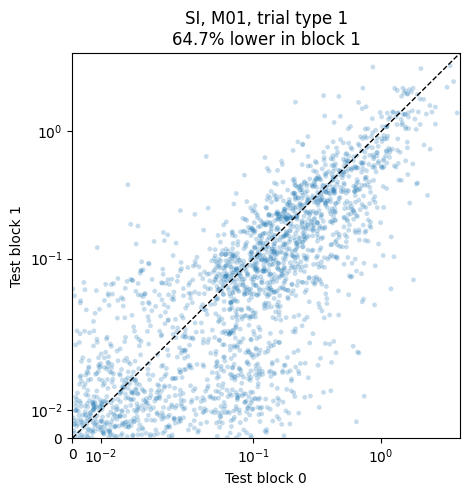

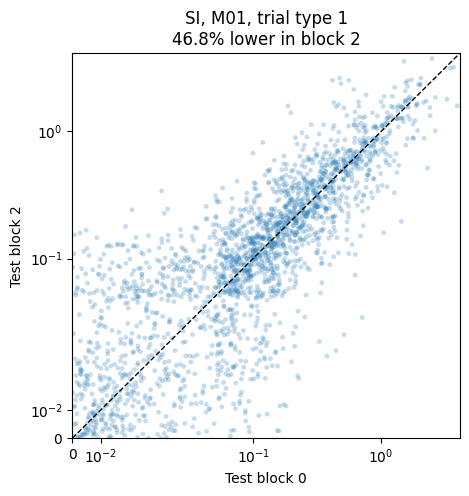

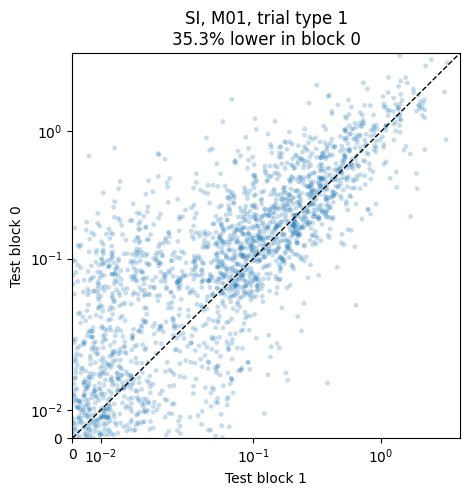

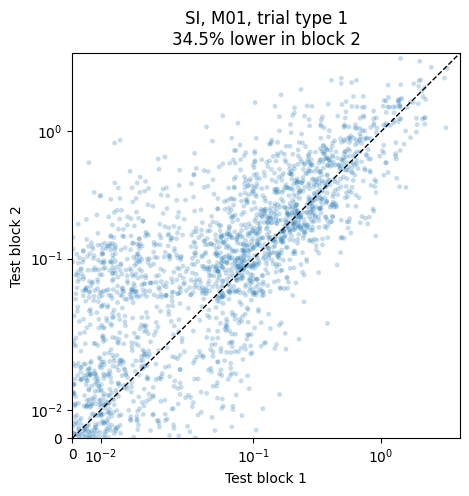

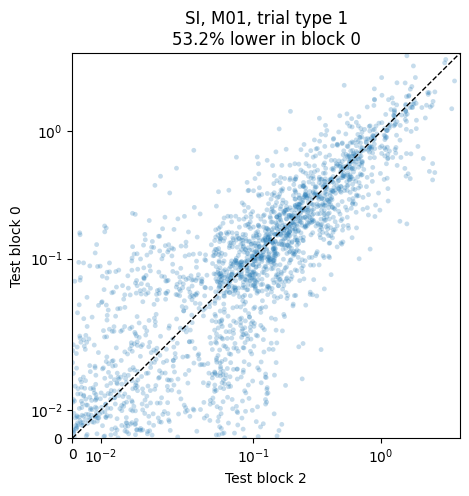

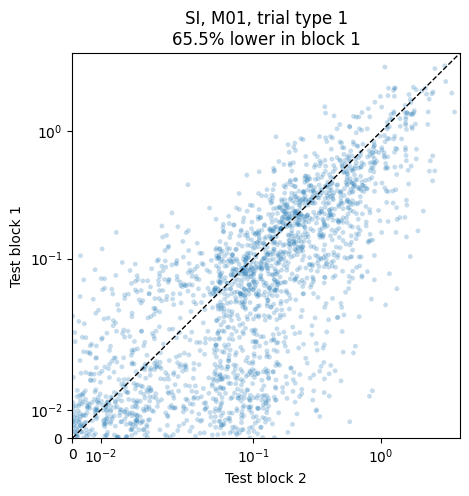

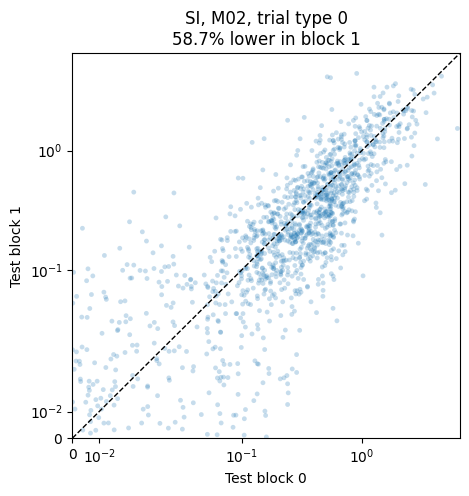

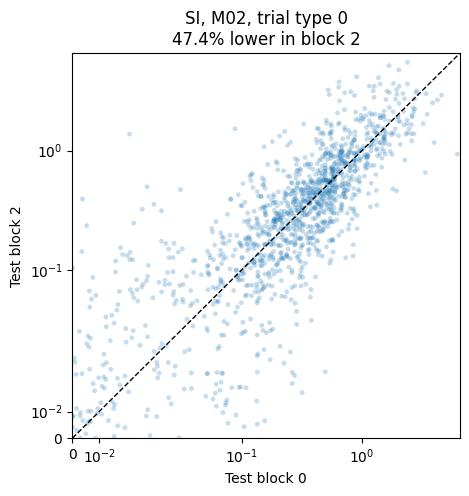

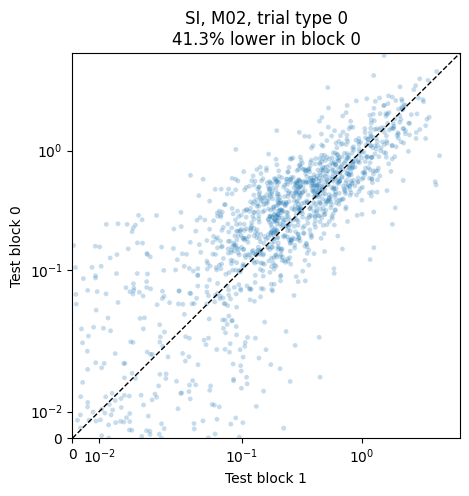

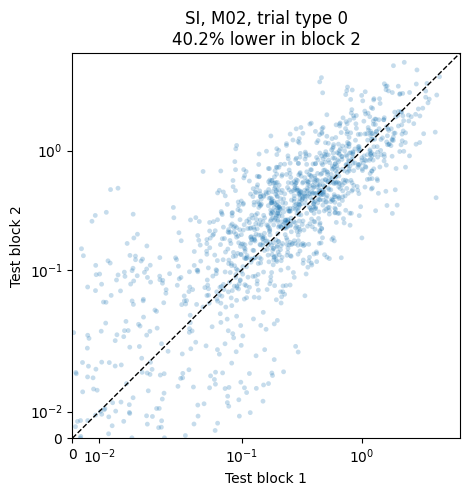

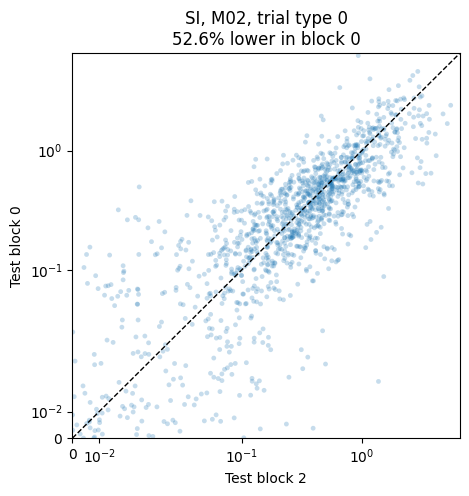

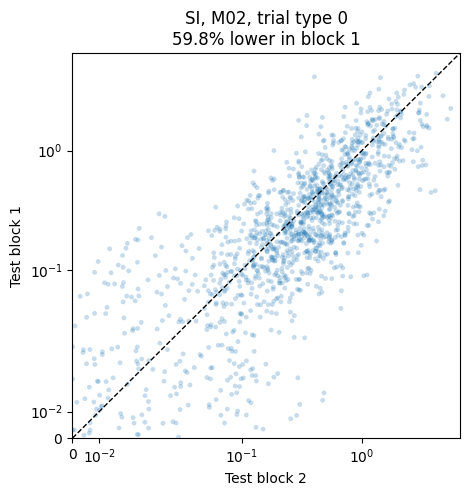

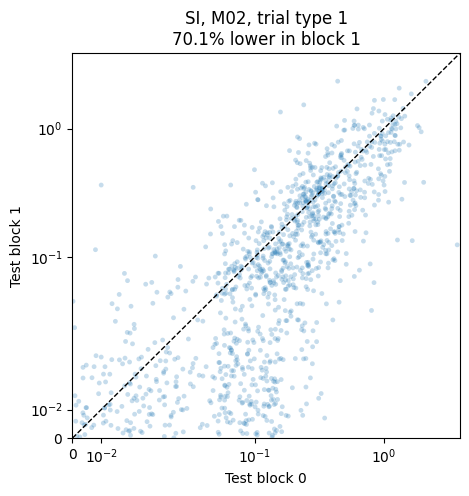

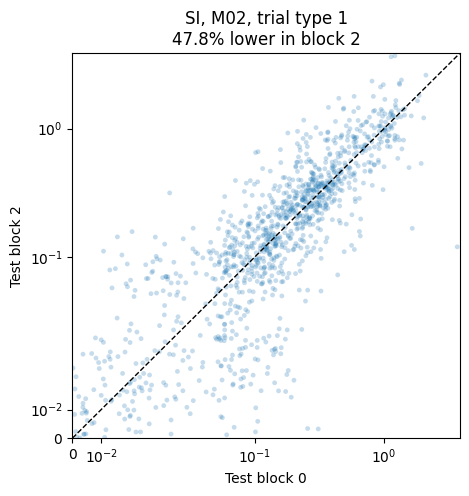

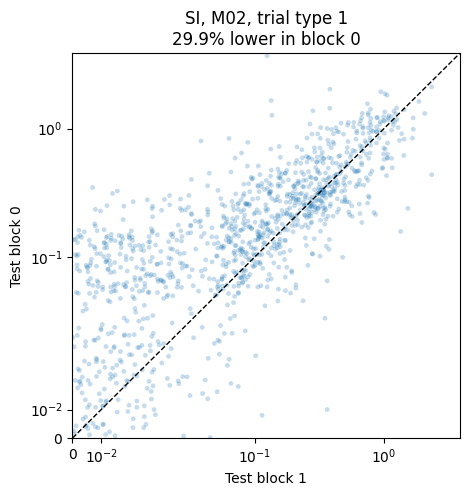

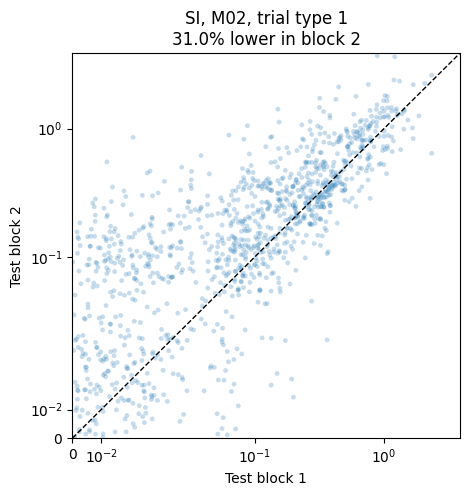

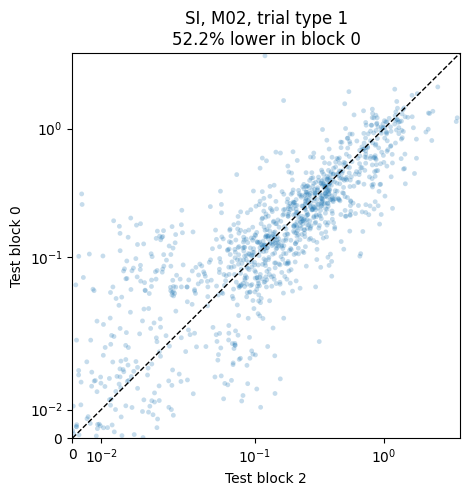

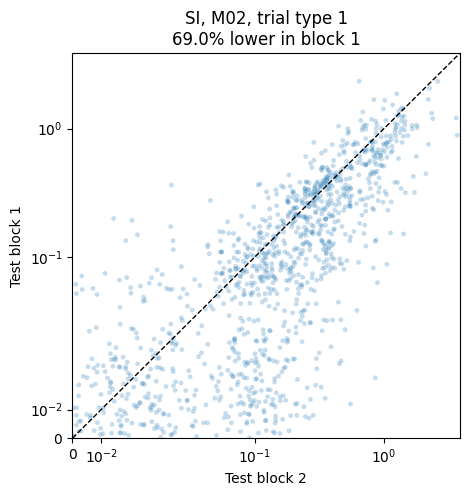

In [50]:
for (mouse, trial_type), group in df_filtered.groupby(["mouse", "trial_type"]):
    si_between_blocks = (
        group.pivot(
            index=["experiment", "day", "session", "unit_id"],
            columns="test_block",
            values="spatial_information",
        )
        .reindex(columns=[0, 1, 2])
        .dropna()
    )
    
    limit = si_between_blocks.to_numpy().max() * 1.05
    for x_axis in [0, 1, 2]:
        for y_axis in [0, 1, 2]:
            if x_axis == y_axis:
                continue
            fig = plt.figure(figsize=(5, 5))
            x = si_between_blocks[x_axis]
            y = si_between_blocks[y_axis]

            plt.scatter(
                x,
                y,
                s=12,
                alpha=0.25,
                edgecolors="none",
            )
            plt.plot(
                [0, limit],
                [0, limit],
                color="black",
                linestyle="--",
                linewidth=1,
            )
            plt.xlim(0, limit)
            plt.ylim(0, limit)
            plt.xlabel(f"Test block {x_axis}")
            plt.ylabel(f"Test block {y_axis}")
            plt.xscale("symlog", linthresh=0.05)
            plt.yscale("symlog", linthresh=0.05)

            proportion_lower = (y < x).mean()
            plt.title(f"SI, {mouse}, trial type {trial_type}\n{proportion_lower:.1%} lower in block {y_axis}")
            plt.show()